# KHÁM PHÁ DỮ LIỆU

Dữ liệu chứa trong file `tips.csv` chứa thông tin tiền tip của khách hàng tại một nhà hàng. Dữ liệu có các thông tin sau:

- `total_bill`: tổng hoá đơn (USD)
- `tip`: tiền tip/ tiền boa (USD)
- `sex`: giới tính người thanh toán hóa đơn
- `smoker`: có hút thuốc hay không
- `day`: ngày trong tuần
- `time`: thời gian dùng bữa(buổi sáng, buổi trưa, buổi tối)
- `size`: số lượng người tham gia

Bạn hãy thực hiện thống kê mô tả để tìm hiểu về hành vi tip của khách hàng tại nhà hàng

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## HIỂU DỮ LIỆU

1. Đọc dữ liệu
2. Xoá cột `Unnamed: 0`
3. Cho biết dữ liệu có bao nhiêu dòng, bao nhiêu thuộc tính.
4. Trong các thuộc tính, thuộc tính nào là thuộc tính phân loại, thuộc tính nào là thuộc tính định lượng
5. Có bao nhiêu nam, bao nhiêu nữ. Tỷ lệ bao nhiêu?
6. Có bao nhiêu người hút thuốc. Tỷ lệ bao nhiêu?
7. Ngày nào trong tuần khách hàng hay đến dùng bữa nhất. Tỷ lệ bao nhiêu?
8. Nhà hàng phục vụ bữa ăn nào nhiều nhất (Breakfast, Lunch, Dinner)?
9. Nhóm khách hàng dùng bữa tại nhà hàng nhiều nhất là bao nhiêu người?
10. Trung bình trong một bữa ăn nhà hàng phục vụ mấy khách?

In [5]:
# 1. Đọc dữ liệu
df = pd.read_csv("T:/TKMT_tuan03/TKMT_lab_03/data/tips.csv")

In [6]:
# 2. Xoá cột `Unnamed: 0`
df = df.drop(columns=["Unnamed: 0"])
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [8]:
# 3. Cho biết dữ liệu có bao nhiêu dòng, bao nhiêu thuộc tính
df.shape

(244, 7)

In [9]:
# 4. Trong các thuộc tính, thuộc tính nào là thuộc tính phân loại, thuộc tính nào là thuộc tính định lượng
df.dtypes

total_bill    float64
tip           float64
sex            object
smoker         object
day            object
time           object
size            int64
dtype: object

In [10]:
#4.1 thuộc tính nào là thuộc tính phân loại
categorical = ["sex", "smoker", "day", "time"]
categorical

['sex', 'smoker', 'day', 'time']

In [11]:
#4.2 thuộc tính nào là thuộc tính định lượng
quantitative = ["total_bill", "tip", "size"]
quantitative

['total_bill', 'tip', 'size']

In [12]:
# 5. Có bao nhiêu nam, bao nhiêu nữ. Tỷ lệ bao nhiêu?
df["sex"].value_counts(normalize=True) * 100

Male      64.344262
Female    35.655738
Name: sex, dtype: float64

In [15]:
#5.1 Nếu muốn hiện số lượng và tỷ lệ trong cùng 1 bảng:
sex = pd.DataFrame({
    "Số lượng": df["sex"].value_counts(),
    "Tỷ lệ (%)": df["sex"].value_counts(normalize=True) * 100
})

sex

,Số lượng,Tỷ lệ (%)
Male,157,64.344262
Female,87,35.655738


In [21]:
# 6. Có bao nhiêu người hút thuốc. Tỷ lệ bao nhiêu?
df["smoker"].value_counts(normalize=True) * 100

No     61.885246
Yes    38.114754
Name: smoker, dtype: float64

In [22]:
# 7. Ngày nào trong tuần khách hàng hay đến dùng bữa nhất. Tỷ lệ bao nhiêu?
df["day"].value_counts(normalize=True) * 100

Sat     35.655738
Sun     31.147541
Thur    25.409836
Fri      7.786885
Name: day, dtype: float64

In [16]:
# 8. Nhà hàng phục vụ bữa ăn nào nhiều nhất (Breakfast, Lunch, Dinner)?
df["time"].value_counts().idxmax()

'Dinner'

In [18]:
# 9. Nhóm khách hàng dùng bữa tại nhà hàng nhiều nhất là bao nhiêu người?
df["size"].value_counts().idxmax()

2

In [19]:
# 10. Trung bình trong một bữa ăn nhà hàng phục vụ mấy khách?
df["size"].mean()

2.569672131147541

## YẾU TỐ ẢNH HƯỞNG ĐẾN TIỀN TIP

Trong phần này, chúng ta thử tìm hiểu về tiền tip tại nhà hàng và các yếu tố có thể ảnh hưởng đến nó

1. Tỷ lệ nhận được tiền tip của nhà hàng là bao nhiêu?
2. Tỷ lệ tiền tip trên tổng hóa đơn là bao nhiêu?
3. Giữa nam và nữ ai tip nhiều tiền hơn, ai tip thường xuyên hơn?
4. Giữa người hút thuốc và người không hút thuốc ai tip nhiều tiền hơn, ai tip thường xuyên hơn?
5. Thống kê tổng số tiền tip nhận được theo ngày.

In [34]:
# 1. Tỷ lệ nhận được tiền tip của nhà hàng là bao nhiêu?
tip_rate = (df["tip"] > 0).mean() * 100
tip_rate

100.0

In [35]:
# 2. Tỷ lệ tiền tip trên tổng hóa đơn là bao nhiêu?
tip_percent = df["tip"].sum() / df["total_bill"].sum() * 100
tip_percent

15.153580224410025

In [31]:
# 3. Giữa nam và nữ ai tip nhiều tiền hơn, ai tip thường xuyên hơn?
df.groupby("sex")["tip"].mean()
df.groupby("sex")["tip"].sum()

sex
Female    246.51
Male      485.07
Name: tip, dtype: float64

In [32]:
# 4. Giữa người hút thuốc và người không hút thuốc ai tip nhiều tiền hơn, ai tip thường xuyên hơn?
df.groupby("smoker")["tip"].mean()
df.groupby("smoker")["tip"].sum()

smoker
No     451.77
Yes    279.81
Name: tip, dtype: float64

In [33]:
# 5. Thống kê tổng số tiền tip nhận được theo ngày
df.groupby("day")["tip"].sum()

day
Fri      51.96
Sat     260.40
Sun     247.39
Thur    171.83
Name: tip, dtype: float64

# TRỰC QUAN DỮ LIỆU

Để dễ hình dung, bạn hãy trực quan với một số câu hỏi sau đây:

1. Vẽ đồ thị thể hiện tổng tiền tip theo ngày
2. Vẽ đồ thị thể hiện tổng tiền tip theo bữa ăn (time)
3. Vẽ đồ thị histogram của tổng hoá đơn
4. Vẽ đồ thị boxplot của tổng hoá đơn
5. Vẽ đồ thị để kiểm tra sự liên quan giữa tổng hoá đơn và tiền tip.
6. So sánh số tiền mà khách hàng đã chi giữa các ngày trong tuần.

## Với Matplotlib

Bạn hãy trực quan với thư viện matplotlib

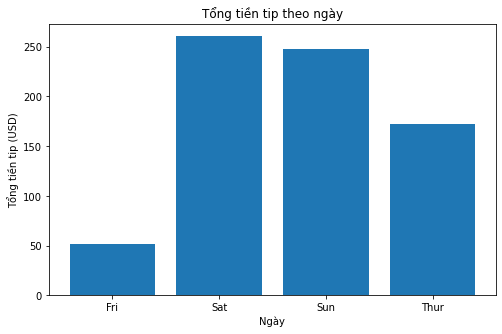

In [43]:
# 1. Vẽ đồ thị thể hiện tổng tiền tip theo ngày
tip_by_day = df.groupby("day")["tip"].sum()

plt.figure(figsize=(8, 5))
plt.bar(tip_by_day.index, tip_by_day.values)

plt.title("Tổng tiền tip theo ngày")
plt.xlabel("Ngày")
plt.ylabel("Tổng tiền tip (USD)")

plt.show()

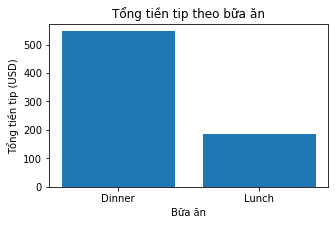

In [46]:
# 2. Vẽ đồ thị thể hiện tổng tiền tip theo bữa ăn (time)
tip_by_time = df.groupby("time")["tip"].sum()

plt.figure(figsize=(5, 3))
plt.bar(tip_by_time.index, tip_by_time.values)

plt.title("Tổng tiền tip theo bữa ăn")
plt.xlabel("Bữa ăn")
plt.ylabel("Tổng tiền tip (USD)")

plt.show()

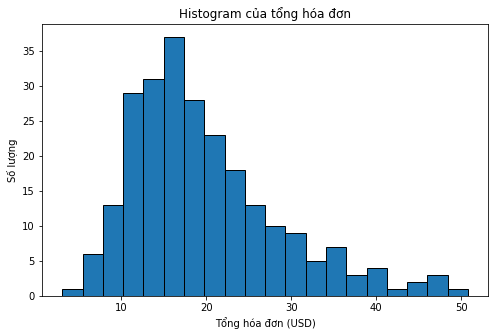

In [47]:
# 3. Vẽ đồ thị histogram của tổng hoá đơn
plt.figure(figsize=(8, 5))

plt.hist(
    df["total_bill"],
    bins=20,
    edgecolor="black"
)

plt.title("Histogram của tổng hóa đơn")
plt.xlabel("Tổng hóa đơn (USD)")
plt.ylabel("Số lượng")

plt.show()

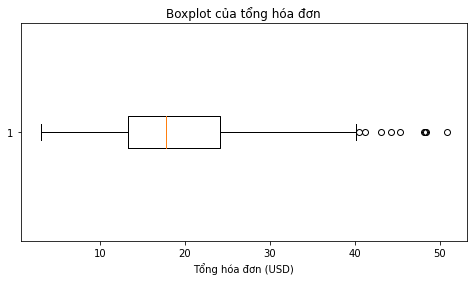

In [48]:
# 4. Vẽ đồ thị boxplot của tổng hoá đơn
plt.figure(figsize=(8, 4))

plt.boxplot(
    df["total_bill"],
    vert=False
)

plt.title("Boxplot của tổng hóa đơn")
plt.xlabel("Tổng hóa đơn (USD)")

plt.show()

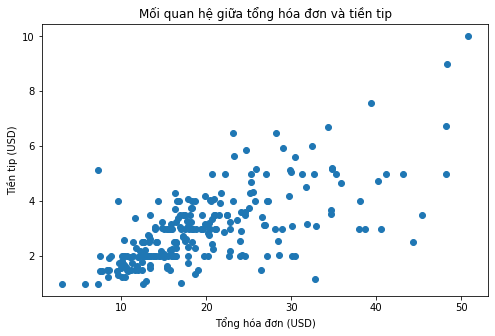

In [49]:
# 5. Vẽ đồ thị để kiểm tra sự liên quan giữa tổng hoá đơn và tiền tip.
plt.figure(figsize=(8, 5))

plt.scatter(
    df["total_bill"],
    df["tip"]
)

plt.title("Mối quan hệ giữa tổng hóa đơn và tiền tip")
plt.xlabel("Tổng hóa đơn (USD)")
plt.ylabel("Tiền tip (USD)")

plt.show()

<Figure size 576x360 with 0 Axes>

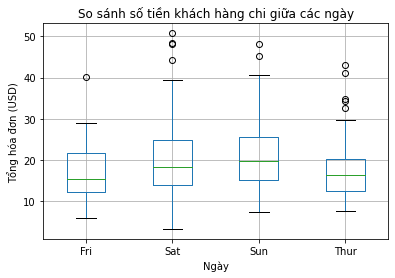

In [50]:
# 6. So sánh số tiền mà khách hàng đã chi giữa các ngày trong tuần.
plt.figure(figsize=(8, 5))

df.boxplot(
    column="total_bill",
    by="day"
)

plt.title("So sánh số tiền khách hàng chi giữa các ngày")
plt.suptitle("")
plt.xlabel("Ngày")
plt.ylabel("Tổng hóa đơn (USD)")

plt.show()

## Với Seaborn

Bạn hãy tìm hiểu và trực quan với thư viện seaborn

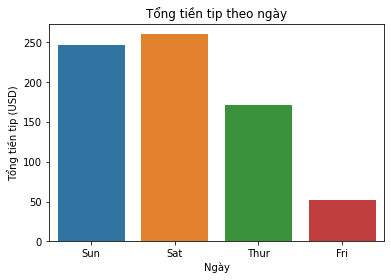

In [54]:
# 1
sns.barplot(
    data=df,
    x="day",
    y="tip",
    estimator=sum,
    ci=None
)

plt.title("Tổng tiền tip theo ngày")
plt.xlabel("Ngày")
plt.ylabel("Tổng tiền tip (USD)")

plt.show()


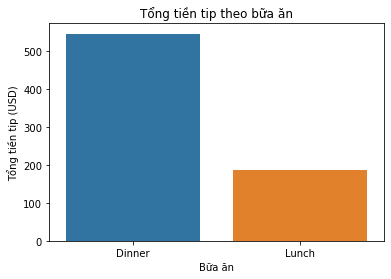

In [55]:
# 2
sns.barplot(
    data=df,
    x="time",
    y="tip",
    estimator=sum,
    ci=None
)

plt.title("Tổng tiền tip theo bữa ăn")
plt.xlabel("Bữa ăn")
plt.ylabel("Tổng tiền tip (USD)")

plt.show()


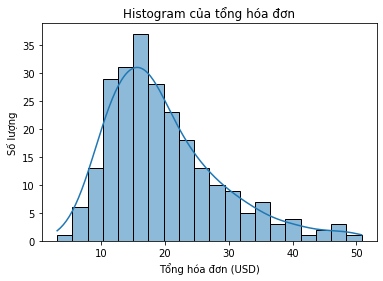

In [56]:
# 3
sns.histplot(
    data=df,
    x="total_bill",
    bins=20,
    kde=True
)

plt.title("Histogram của tổng hóa đơn")
plt.xlabel("Tổng hóa đơn (USD)")
plt.ylabel("Số lượng")

plt.show()


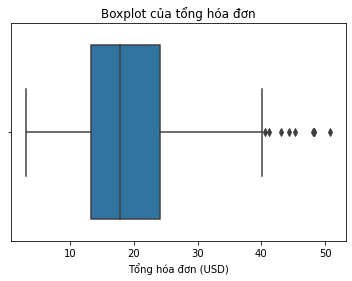

In [57]:
# 4
sns.boxplot(
    data=df,
    x="total_bill"
)

plt.title("Boxplot của tổng hóa đơn")
plt.xlabel("Tổng hóa đơn (USD)")

plt.show()


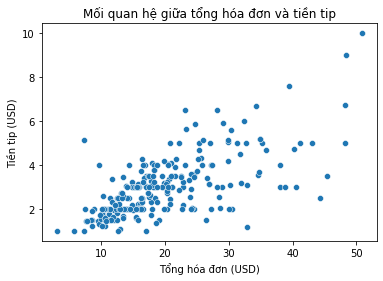

In [58]:
# 5
sns.scatterplot(
    data=df,
    x="total_bill",
    y="tip"
)

plt.title("Mối quan hệ giữa tổng hóa đơn và tiền tip")
plt.xlabel("Tổng hóa đơn (USD)")
plt.ylabel("Tiền tip (USD)")

plt.show()


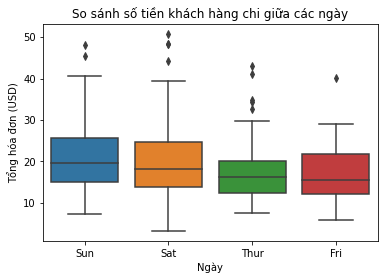

In [59]:
# 6
sns.boxplot(
    data=df,
    x="day",
    y="total_bill"
)

plt.title("So sánh số tiền khách hàng chi giữa các ngày")
plt.xlabel("Ngày")
plt.ylabel("Tổng hóa đơn (USD)")

plt.show()
